# Book construction: from scores to a tradable, costed book

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leon1706-lol/Aether-quant/blob/main/notebooks/02_book_construction.ipynb)

One signal, the 20-day momentum of 11 coins, taken through each step a book goes through:

1. **A rank book.** Long the top names and short the bottom ones, with `build_rank_based_book`, the function the live algorithm calls.
2. **Neutrality.** Dollar neutrality with per-name caps (`apply_book_neutrality`), then beta neutrality against BTC.
3. **Allocation and sizing.** Hierarchical risk parity, volatility targeting and fractional Kelly.
4. **Costs.** Composable cost models, and `backtest()` with and without them.

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: install the library (numpy and pandas come with it)
    get_ipython().run_line_magic("pip", 'install -q "aether-quant[notebooks]"')  # noqa: F821
else:  # a clone: run against the checkout's code
    for parent in (Path.cwd(), *Path.cwd().parents):
        if (parent / "aether_quant" / "__init__.py").is_file():
            sys.path.insert(0, str(parent))
            break

In [2]:
import pandas as pd

from aether_quant import backtest, costs, neutrality, portfolio, samples, sizing

closes = samples.load_sample_prices().loc["2023-07-13":]
opens = samples.load_sample_prices("open").loc[closes.index]
returns = closes.pct_change(fill_method=None)
momentum = closes / closes.shift(20) - 1

## 1. A rank book on one day

`build_rank_based_book` takes each name's predicted rank, here the momentum percentile, and returns the long and short slots with the reason for each.

In [3]:
day = "2025-03-03"
ranks = momentum.loc[day].rank(pct=True)
candidates = {ticker: {"predicted_rank_20d": float(rank), "trading_eligible": True, "asset_class": "crypto"} for ticker, rank in ranks.items()}
book = portfolio.build_rank_based_book(candidates, top_n=3, bottom_n=3)
pd.DataFrame({ticker: {"role": alloc.role, "rank": round(alloc.predicted_rank_20d, 2), "reason": alloc.book_reason} for ticker, alloc in book.items()}).T

,role,rank,reason
ADAUSD,long,1.0,rank_based_book_long
ZECUSD,long,0.91,rank_based_book_long
XRPUSD,long,0.82,rank_based_book_long
LINKUSD,short,0.09,rank_based_book_short
DOGEUSD,short,0.18,rank_based_book_short
ETHUSD,short,0.27,rank_based_book_short


## 2. Neutrality: dollars, then beta

Equal raw weights become a dollar-neutral book with a 20% per-name cap. Crypto names have very different betas to BTC, so a dollar-neutral book can still carry a market bet. `beta_neutralize` removes it with the smallest change to the weights.

In [4]:
raw = {ticker: (0.3 if alloc.role == "long" else -0.3) for ticker, alloc in book.items()}
dollar_neutral, steps = neutrality.apply_book_neutrality(
    raw, sector_by_symbol={ticker: "crypto" for ticker in raw}, dollar_neutral=True, sector_neutral=False, gross_exposure_cap=1.0,
    max_weight_per_name=0.2, sector_max_net_weight=1.0,
)
betas = neutrality.estimate_betas(returns.loc[:day], returns["BTCUSD"].loc[:day], window=120).to_dict()
beta_neutral = neutrality.beta_neutralize(dollar_neutral, betas)
print(f"net beta to BTC: dollar neutral {neutrality.net_beta(dollar_neutral, betas):+.3f}, beta neutral {neutrality.net_beta(beta_neutral, betas):+.6f}")
print("neutrality steps:", steps["steps_applied"])
pd.DataFrame({"raw": raw, "dollar neutral": dollar_neutral, "beta neutral": beta_neutral, "beta to BTC": betas}).loc[list(raw)].round(3)

net beta to BTC: dollar neutral +0.021, beta neutral -0.000000
neutrality steps: ['per_name_cap', 'dollar_neutral', 'gross_cap']


,raw,dollar neutral,beta neutral,beta to BTC
ADAUSD,0.3,0.167,0.164,2.068
ZECUSD,0.3,0.167,0.165,1.028
XRPUSD,0.3,0.167,0.165,1.383
LINKUSD,-0.3,-0.167,-0.169,1.346
DOGEUSD,-0.3,-0.167,-0.169,1.874
ETHUSD,-0.3,-0.167,-0.168,1.134


## 3. Allocation and sizing

These three answer different questions:

- **HRP:** how to split risk across correlated names without inverting a noisy covariance matrix.
- **Volatility targeting:** how big the whole book should be.
- **Kelly:** the growth-optimal size if the expected returns were known. They never are, so the default is half Kelly with a cap.

In [5]:
history = returns.loc["2024-03-01":day].dropna(axis=1)
hrp = portfolio.compute_hrp_weights(history)
scaled = sizing.volatility_target_weights(hrp.to_dict(), history.cov(), target_annual_vol=0.10, max_leverage=1.0, annualization=365)
mu = history.mean().to_numpy() * 0.25  # a shrunk view of expected returns; the raw sample mean is far too noisy for Kelly
half_kelly = sizing.kelly_weights(mu, history.cov().to_numpy(), fraction=0.5, gross_cap=1.0)
pd.DataFrame({"HRP": hrp, "HRP at 10% vol": pd.Series(scaled), "half Kelly (capped)": pd.Series(half_kelly, index=history.columns)}).round(3)

,HRP,HRP at 10% vol,half Kelly (capped)
ADAUSD,0.036,0.005,-0.025
BCHUSD,0.052,0.008,0.026
BTCUSD,0.195,0.029,0.249
DOGEUSD,0.074,0.011,0.048
ETCUSD,0.150,0.022,-0.163
ETHUSD,0.113,0.017,-0.200
LINKUSD,0.052,0.008,-0.045
LTCUSD,0.074,0.011,0.028
XLMUSD,0.070,0.010,0.013
XRPUSD,0.099,0.015,0.157


## 4. Costs, and a backtest with and without them

A cost model answers one question: what does one trade cost, in basis points? Models add up. The presets are the fees the live path charges, so a research cost and a live cost are the same numbers.

In [6]:
coinbase = costs.coinbase_model()
impact = costs.CompositeCostModel((costs.LinearCostModel(commission_bps=5.0, half_spread_bps=2.0), costs.SquareRootImpactModel(eta=1.0)))
print("Coinbase market order:", coinbase.cost_bps(10_000.0), "bps")
print("5 bps + 2 bps spread + impact, $1M into $50M ADV at 3% daily vol:", round(impact.cost_bps(1e6, adv_usd=5e7, daily_vol=0.03), 1), "bps")

Coinbase market order: 90.0 bps
5 bps + 2 bps spread + impact, $1M into $50M ADV at 3% daily vol: 49.4 bps


In [7]:
rank = momentum.rank(axis=1, pct=True)
signal_weights = rank.sub(rank.mean(axis=1), axis=0)
signal_weights = signal_weights.div(signal_weights.abs().sum(axis=1), axis=0)  # dollar neutral, gross 1
weekly = signal_weights.where(pd.Series(range(len(signal_weights)), index=signal_weights.index) % 7 == 0)  # decide once a week
start = "2023-09-01"
runs = {
    "no costs": backtest.backtest(weekly.loc[start:], closes.loc[start:], opens=opens.loc[start:], periods_per_year=365),
    "Coinbase costs": backtest.backtest(weekly.loc[start:], closes.loc[start:], opens=opens.loc[start:], cost_model=coinbase, periods_per_year=365),
}
pd.DataFrame({name: run.stats() for name, run in runs.items()}).loc[["cagr", "sharpe_ratio", "max_drawdown", "turnover_annual", "cost_drag_bps_annual"]].round(3)

,no costs,Coinbase costs
cagr,0.455,-0.001
sharpe_ratio,1.932,0.130
max_drawdown,0.232,0.405
turnover_annual,41.726,41.890
cost_drag_bps_annual,0.000,3770.089


## Turnover against cost

The same book at rising cost levels. A signal that only works below the venue's real cost is not a signal you can trade.

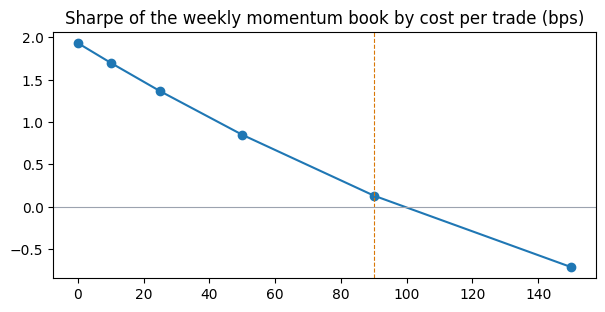

In [8]:
import matplotlib.pyplot as plt

levels = [0, 10, 25, 50, 90, 150]
sweep = pd.Series({bps: backtest.backtest(weekly.loc[start:], closes.loc[start:], opens=opens.loc[start:], cost_model=costs.LinearCostModel(commission_bps=bps),
                                          periods_per_year=365).stats()["sharpe_ratio"] for bps in levels})
axes = sweep.plot(marker="o", figsize=(7, 3.2), title="Sharpe of the weekly momentum book by cost per trade (bps)")
axes.axvline(90, color="#d97706", linestyle="--", linewidth=0.8)
axes.axhline(0, color="#9ca3af", linewidth=0.8)
plt.show()

**Next:** [03 overfitting tests](03_overfitting_tests.ipynb). How much of a backtest's Sharpe survives the search that found it?